## 1. Data import

## 1.1. Package import

In [1]:

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib import colormaps

## 1.2. Network import from edge list


Graph with 51 nodes and 110 edges



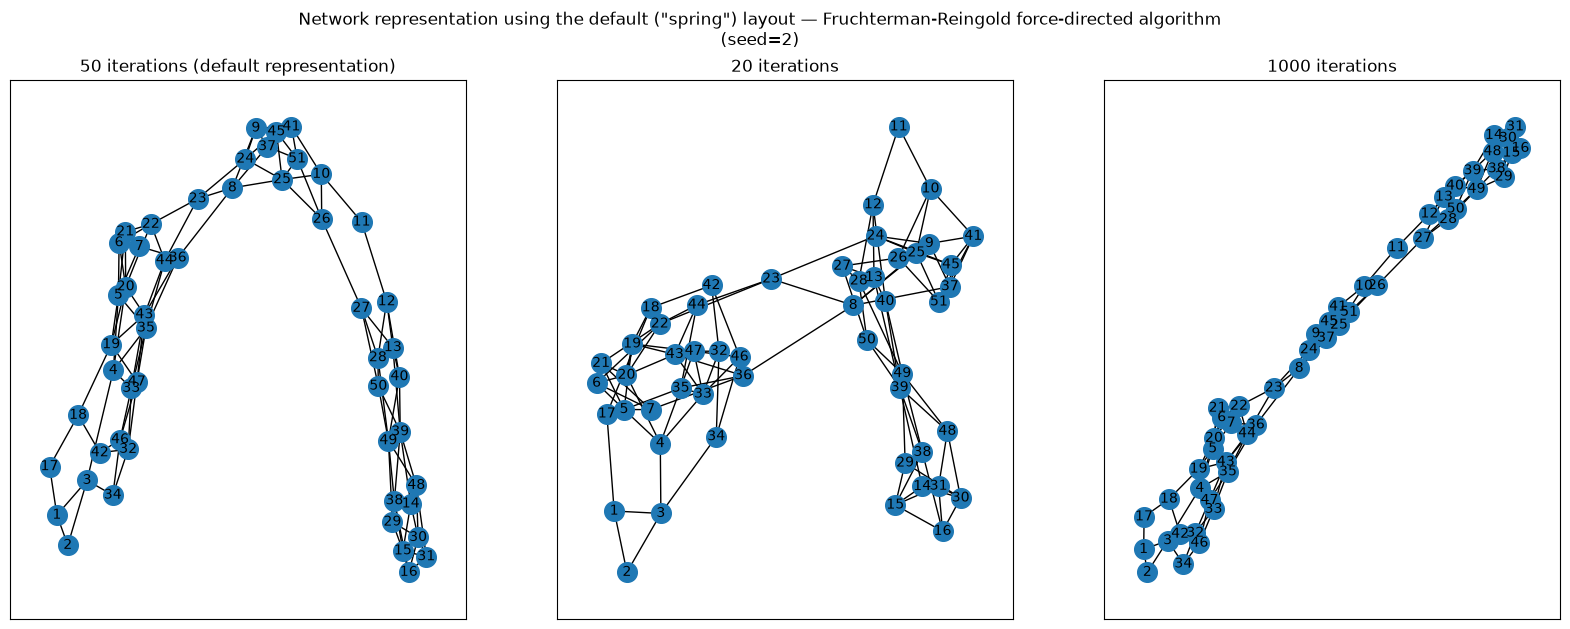

In [2]:
G = nx.read_edgelist('./edgelist.txt') # I create the graph based on the provided edge list
print(f"\n{G}\n")

spring_layout = nx.spring_layout(G, seed=2, iterations=20) # I choose a fixed layout; this keeps the nodes in the same positions accross different networks
spring1000_layout = nx.spring_layout(G, seed=2, iterations=1000) # different layout for the purpose of illustrating the difference the no. of iterations makes

fig_init = plt.figure(figsize=(20, 7))
plt.suptitle("Network representation using the default (\"spring\") layout — Fruchterman-Reingold force-directed algorithm\n(seed=2)")

fig_init.add_subplot(131, title="50 iterations (default representation)")
nx.draw_networkx(G, with_labels=True, node_size=200, font_size=10, pos=nx.spring_layout(G, seed=2))

fig_init.add_subplot(132, title="20 iterations")
nx.draw_networkx(G, with_labels=True, pos=spring_layout, node_size=200, font_size=10)

fig_init.add_subplot(133, title="1000 iterations")
nx.draw_networkx(G, with_labels=True, pos=spring1000_layout, node_size=200, font_size=10)

plt.show()


We use networkx's ```read_edgelist``` function. We can see that, despite having 220 entries in the original edge list, the created graph has only 110; this is because the Graph object in networkx is by default undirected.

The network represents the structure of an enzyme; the nodes are the atoms that make up the enzyme, and the edges are the interactions (chemical or physical) that exist between those atoms. 

As we can see, the higher the number of iterations of the Fruchterman-Reingold force-directed algorithm, the more linear the network representations becomes, and the nodes become more indistinguishable from one another. For this reason, I will use the **20-iterations layout**, which has a better visual separation of the nodes, for this assignment.

# 2. First-order properties

## 2.1. Topology analysis

In [3]:
N = G.number_of_nodes()
L = G.number_of_edges()
avg_degree = 2 * L / N
density = nx.density(G)

components = list(nx.connected_components(G)) # I check if the network has one or more components
graph_size = len(G)
avg_path_length = nx.average_shortest_path_length(G)
diameter = nx.diameter(G)

print("=" * 40)
print("GLOBAL TOPOLOGY & COMPONENT ANALYSIS")
print("=" * 40)
print(f"Number of nodes (N):        {N}")
print(f"Number of edges (L):        {L}")
print(f"Average Degree <k>:         {avg_degree:.4f}")
print(f"Network Density:            {density:.6f}")
print(f"Connected Components:       {len(components)}")
print(f"Component Size:             {graph_size} nodes")
print(f"Average Walk Length:        {avg_path_length:.4f}")
print(f"Network Diameter:           {diameter}")

GLOBAL TOPOLOGY & COMPONENT ANALYSIS
Number of nodes (N):        51
Number of edges (L):        110
Average Degree <k>:         4.3137
Network Density:            0.086275
Connected Components:       1
Component Size:             51 nodes
Average Walk Length:        5.0424
Network Diameter:           12


**Observation**: The graph only has one connected component, of 51 nodes and 110 edges.  
**Interpretation**: The graph is **not** a fully-connected graph, as $L \ll \frac{N * (N - 1)}{2}$ .

## 2.2. Degree distribution

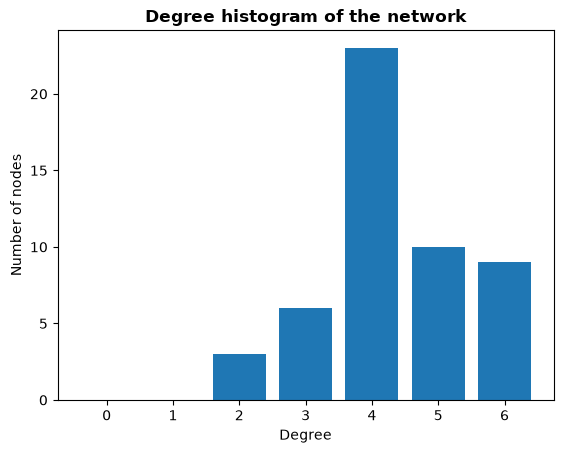

In [4]:
degree_distribution = nx.degree_histogram(G)

plt.bar(range(len(degree_distribution)), degree_distribution) # no node in the provided graph has degree 0 or 1, but we want to see them on the plot 
                                                                # => we use the length of the distribution as x-axis values
plt.title("Degree histogram of the network", fontweight="bold")
plt.xlabel("Degree")
plt.ylabel("Number of nodes")

plt.show()

**Interpretation**: Most nodes are well connected and that the are no dangling or isolated nodes. The histogram also reflects the average degree of 4.3137.

**Note**: normally, degree distributions are represented by line charts. In this case however, the small range of node degrees and the non-heavy-tailed distribution make a histogram a better visualisation tool.

# 3. Higher-order properties

## 3.1. Network randomisation

In order to verify if the network's higher order properties are a result of its degree distribution, we randomise it by swapping edges while preserving the degree of each node, in order to obtain a null model for comparison.

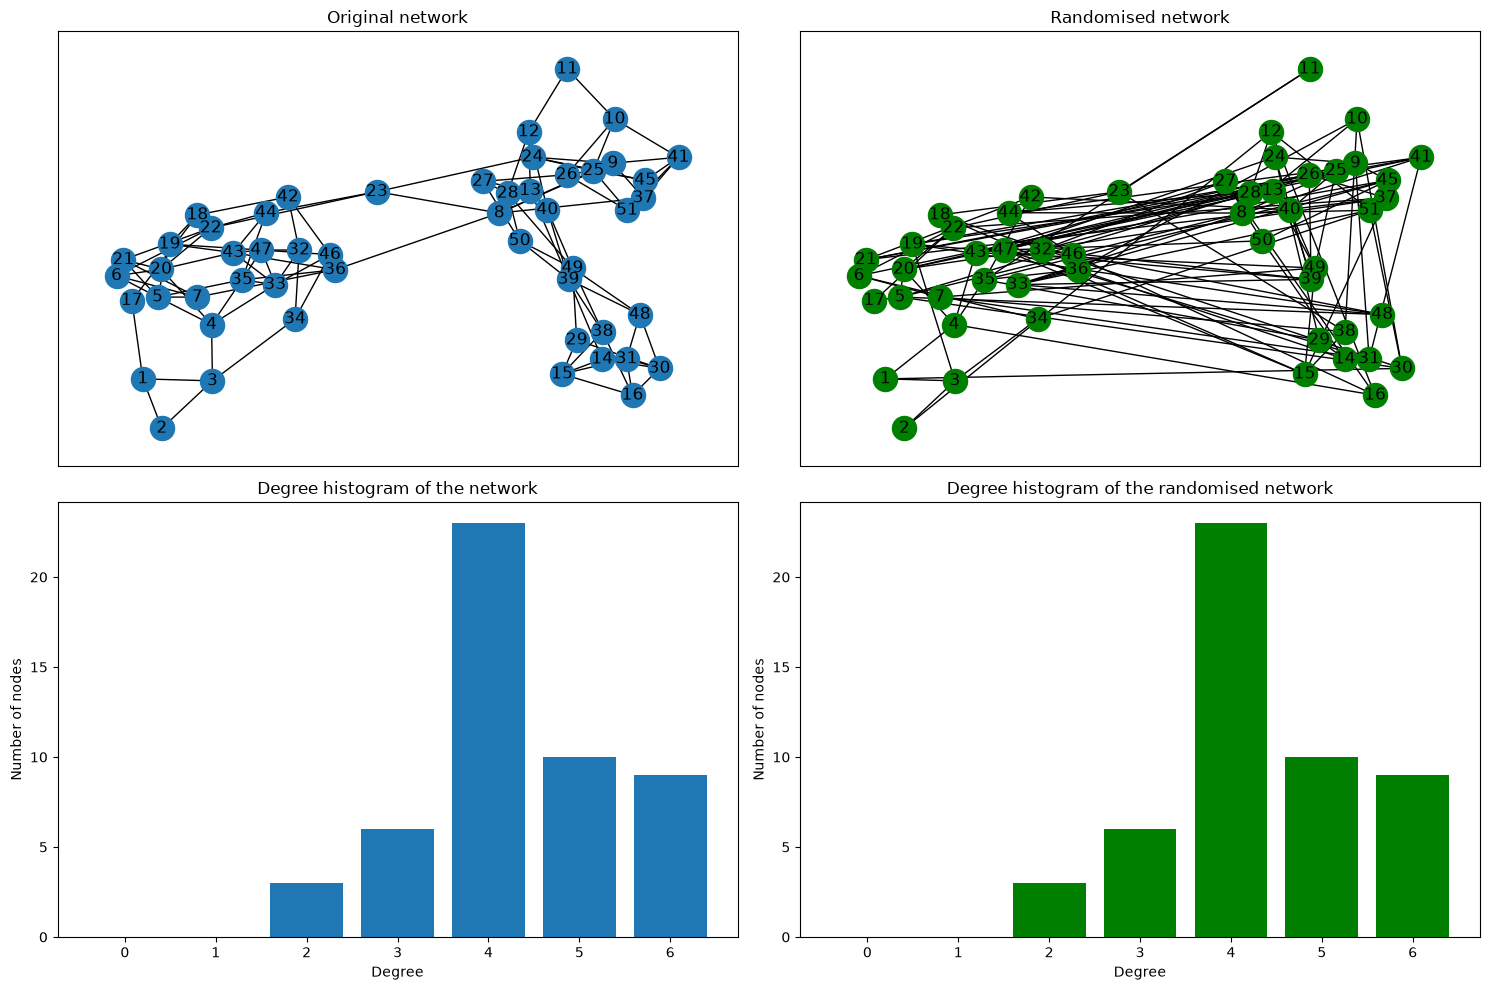

GLOBAL TOPOLOGY & COMPONENT ANALYSIS — NULL MODEL
Number of nodes (N):        51
Number of edges (L):        110
Average Degree <k>:         4.3137
Network Density:            0.086275
Connected Components:       1
Component Size:             51 nodes
Average Walk Length:        2.8000
Network Diameter:           5


In [5]:
G_rand = nx.random_reference(G, seed=15) # the randomised network

degree_distribution = nx.degree_histogram(G)
G_rand_degree_distribution = nx.degree_histogram(G_rand)

fig_new_rand_graphs = plt.figure(figsize=(15, 10))

fig_new_rand_graphs.add_subplot(221, title="Original network")
nx.draw_networkx(G, pos=spring_layout)

fig_new_rand_graphs.add_subplot(222, title="Randomised network")
nx.draw_networkx(G_rand, pos=spring_layout, node_color="green")

fig_new_rand_graphs.add_subplot(223, title="Degree histogram of the network", xlabel="Degree", ylabel="Number of nodes")
plt.bar(range(len(degree_distribution)), degree_distribution) # no node in the provided graph has degree 0 or 1, but we want to see them on the plot => we use the 
                                                                    # length of the distribution as x-axis values

fig_new_rand_graphs.add_subplot(224, title="Degree histogram of the randomised network", xlabel="Degree", ylabel="Number of nodes")
plt.bar(range(len(G_rand_degree_distribution)), G_rand_degree_distribution, color='green') 

plt.tight_layout()
plt.show()

N_r = G_rand.number_of_nodes()
L_r = G_rand.number_of_edges()
avg_degree_r = 2 * L_r / N_r
density_r = nx.density(G_rand)

components_r = list(nx.connected_components(G_rand))
graph_size_r = len(G_rand)
avg_path_length_r = nx.average_shortest_path_length(G_rand)
diameter_r = nx.diameter(G_rand)

print("=" * 50)
print("GLOBAL TOPOLOGY & COMPONENT ANALYSIS — NULL MODEL")
print("=" * 50)
print(f"Number of nodes (N):        {N_r}")
print(f"Number of edges (L):        {L_r}")
print(f"Average Degree <k>:         {avg_degree_r:.4f}")
print(f"Network Density:            {density_r:.6f}")
print(f"Connected Components:       {len(components_r)}")
print(f"Component Size:             {graph_size_r} nodes")
print(f"Average Walk Length:        {avg_path_length_r:.4f}")
print(f"Network Diameter:           {diameter_r}")


The original network has a structure that gives the impression we might be able to identify clusters or important nodes visually. This impression disappears completely in the randomised network. However, the degree histogram shows us that the nodes kept their degrees through the randomisation.

**Note**: visually, it might seem that some nodes, like 1, 2, 3, or 11, did not keep their degrees. This is just an illusion caused by overlapping edges, as we can see in the cell below.

In [6]:
print("Node ID  | Node degree in G  | Node degree in randomised G")
print('-'*60)
print(f"11       |    {len([i for i in G.neighbors('11')])}              |    {len([i for i in G_rand.neighbors('11')])}")
print(f"1        |    {len([i for i in G.neighbors('1')])}              |    {len([i for i in G_rand.neighbors('1')])}")
print(f"2        |    {len([i for i in G.neighbors('2')])}              |    {len([i for i in G_rand.neighbors('2')])}")
print(f"3        |    {len([i for i in G.neighbors('3')])}              |    {len([i for i in G_rand.neighbors('3')])}")

Node ID  | Node degree in G  | Node degree in randomised G
------------------------------------------------------------
11       |    2              |    2
1        |    3              |    3
2        |    2              |    2
3        |    4              |    4


## 3.2. Global clustering

In [7]:
G_clustering_coeff = nx.average_clustering(G)
G_rand_clustering_coeff = nx.average_clustering(G_rand)

## 3.3. Assortativity

In [8]:
# G_deg_assort_coeff = nx.degree_assortativity_coefficient(G)
G_pears_assort_coeff = nx.degree_pearson_correlation_coefficient(G) # same as degree_assortativity_coefficient
G_annd = nx.average_degree_connectivity(G)

# G_rand_deg_assort_coeff = nx.degree_assortativity_coefficient(G_rand)
G_rand_pears_assort_coeff = nx.degree_pearson_correlation_coefficient(G_rand)
G_rand_annd = nx.average_degree_connectivity(G_rand)

## 3.4. Comparison between the original and randomised network

HIGHER ORDER PROPERTIES AND COMPARISON WITH RANDOMISED NETWORK

Property                |  Original network  | Randomised network 
----------------------------------------------------------------------
Clustering coefficient  |  0.237908          | 0.030719
Assortativity (Pearson) |  0.169262          | 0.057926


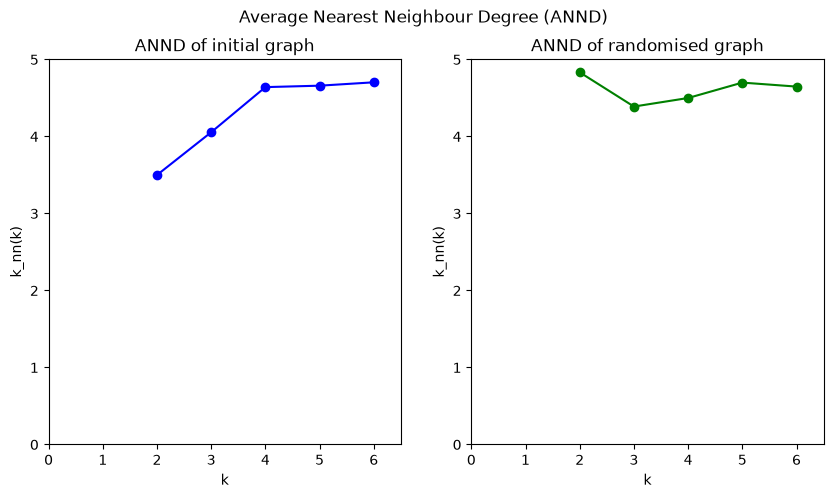

In [9]:
print("=" * 63)
print("HIGHER ORDER PROPERTIES AND COMPARISON WITH RANDOMISED NETWORK")
print("=" * 63 + '\n')
print("Property                |  Original network  | Randomised network ")
print('-' * 70)
print(f"Clustering coefficient  |  {G_clustering_coeff:.6f}          | {G_rand_clustering_coeff:.6f}")
print(f"Assortativity (Pearson) |  {G_pears_assort_coeff:.6f}          | {G_rand_pears_assort_coeff:.6f}")
# print(f"Assortativity (Degree)  |  {G_deg_assort_coeff:.6f}          | {G_rand_deg_assort_coeff:.6f}")

y_G = list(G_annd.values())
x_G = list(G_annd.keys())

x_G_rand = list(G_rand_annd.keys())
y_G_rand = list(G_rand_annd.values())

fig_annds = plt.figure(figsize=(10, 5))
plt.suptitle("Average Nearest Neighbour Degree (ANND)")

fig_annds.add_subplot(121, title="ANND of initial graph", xlabel="k", ylabel="k_nn(k)")
plt.axis((0, 6.5, 0, 5))
plt.plot(x_G, y_G, '-ob')

fig_annds.add_subplot(122, title="ANND of randomised graph", xlabel="k", ylabel="k_nn(k)")
plt.axis((0, 6.5, 0, 5))
plt.plot(x_G_rand, y_G_rand, '-og')

plt.show()

**Observations**:  
1. The higher order properties of the randomised graph are different from those of the original.
2. For the original network, $k_{nn}(k)$ is ascending.
3. For the randomised network, $k_{nn}(k)$ is neither ascending nor descending.

**Interpretations**:  
1. The properties of the initial graph do not stem from the degree distribution, there is another process that explains them.
2. The original network is **assortative**, meaning well-connected nodes tend to connect to other well-connected nodes.
3. Random networks tend to eliminate node connectivity preferences. 

## 3.5. Local Clustering

The nodes with the highest clustering coefficient are (node-value pairs):
	[('2', 1.0), ('37', 0.5), ('16', 0.5), ('31', 0.5), ('45', 0.5), ('51', 0.5), ('41', 0.4), ('1', 0.3333333333333333)]


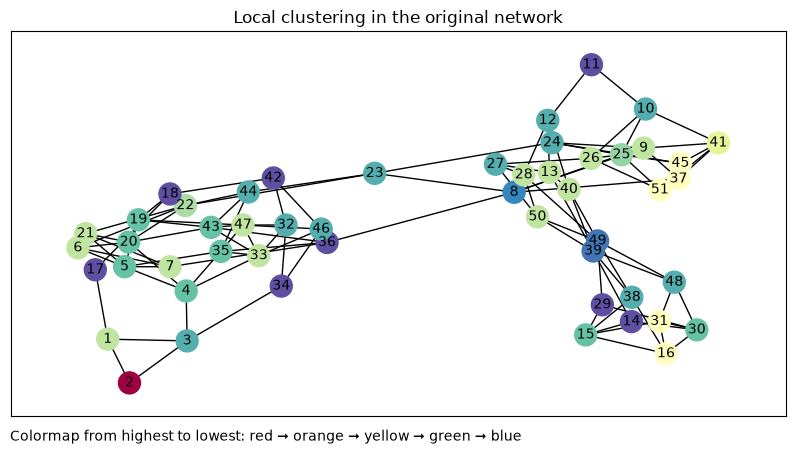

In [10]:
G_local_clust = nx.clustering(G)
clust_vals = [v for k, v in G_local_clust.items()]

print("The nodes with the highest clustering coefficient are (node-value pairs):" +
      f"\n\t{[(k, v) for k, v in sorted(G_local_clust.items(), key=lambda item: item[1], reverse=True)][:8]}")

plt.figure(figsize=(10, 5))
plt.title("Local clustering in the original network")

nx.draw_networkx(G, 
        node_color=clust_vals, 
        cmap=colormaps.get_cmap('Spectral_r'), 
        vmin=min(clust_vals), 
        vmax=max(clust_vals), 
        pos=spring_layout,
        node_size=250,
        font_size=10
    )

# because of the huge jump from the highest to second-highest clustering value, the high-to-low colour
    # progression might not be obvious; I add a note on the image explaining what that progression is.
plt.text(-1.2, -1.2, "Colormap from highest to lowest: red ➞ orange ➞ yellow ➞ green ➞ blue")
plt.show()

Despite being on the edge of the network, node 2 has the highest clustering coefficient, which is also significantly higher than the second highest (1 vs. 0.5). This is because node 2 is only connected to nodes 1 and 3; since nodes 1 and 3 are also connceted with each other, node 2 forms closed triangles with all its neighbours, hence the coefficient value of 1.

The nodes with the second highest clustering coefficient are interconnected: 37, 51, and 45, respectively 31 and 16. This suggests they are part of local cliques or functional cores.

## 3.6. Centrality

### 3.6.1. Degree centrality

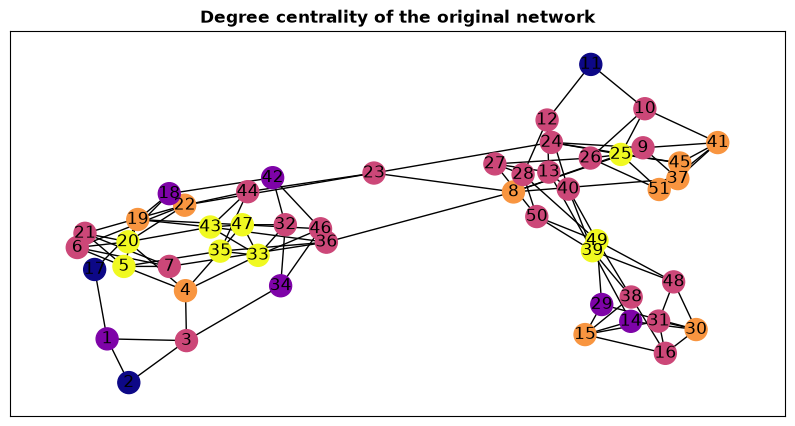

The highest degree of the network's nodes is k=0.12
The nodes with the highest degree centrality are [5, 20, 33, 35, 25, 39, 43, 47, 49]


In [11]:

G_deg_centr = nx.degree_centrality(G)
# I create a list of only the centrality values, to use for the heatmap colouring of the network when representing the nodes' centrality
dcentr_vals = [v for k, v in G_deg_centr.items()]

rGr_deg_centr = nx.degree_centrality(G_rand)
dcentr_vals_rGr = [v for k, v in rGr_deg_centr.items()]

plt.figure(figsize=(10, 5))
plt.title("Degree centrality of the original network", fontweight="bold")

nx.draw_networkx(G, 
        node_color=dcentr_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(dcentr_vals), 
        vmax=max(dcentr_vals), 
        pos=spring_layout,
        node_size=250
    )
plt.show()

# I calculate the highest degree centrality and identify the nodes with this centrality
max_Gdc = max(G_deg_centr.values())
highest_centr = []
for i in G_deg_centr:
    if G_deg_centr[i] == max_Gdc:
        highest_centr.append(i)

print(f"The highest degree of the network's nodes is k={max_Gdc}\nThe nodes with the highest degree centrality are {[int(i) for i in highest_centr]}")

Grand_deg_centr = nx.degree_centrality(G_rand)
max_Grdc = max(Grand_deg_centr.values())
highest_centr_rand = []
for i in Grand_deg_centr:
    if Grand_deg_centr[i] == max_Grdc:
        highest_centr_rand.append(i)

**Observations**:  nodes 5, 20, 33, 35, 25, 39, 43, 47, 49 have the highest degree centrality in the network.  
**Interpretation**: These nodes serve as densely connected local hubs; in the context of an enzyme, they might have the highest number of physical or chemical interactions in the structure.

### 3.6.2. Closeness centrality

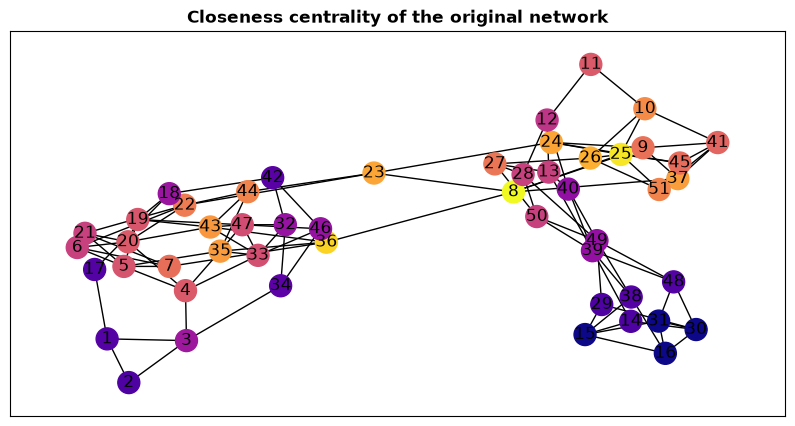

In [12]:
G_close_centr = nx.closeness_centrality(G)
ccentr_vals = [v for k, v in G_close_centr.items()] # centrality list for heatmap

rGr_close_centr = nx.closeness_centrality(G_rand) # rGr = random graph from random_reference; didn't want to risk replacing it
ccentr_vals_rGr = [v for k, v in rGr_close_centr.items()] # centrality list for heatmap

plt.figure(figsize=(10, 5))
plt.title("Closeness centrality of the original network", fontweight="bold")

nx.draw_networkx(G, 
        node_color=ccentr_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(ccentr_vals), 
        vmax=max(ccentr_vals), 
        pos=spring_layout,
        node_size=250
    )
plt.show()

# I identify the 8 most central nodes in the two networks
highest_Gcc_nodes = [k for k, v in sorted(G_close_centr.items(), key=lambda item: item[1], reverse=True)][:8]
highest_Grandcc_nodes = [k for k, v in sorted(rGr_close_centr.items(), key=lambda item: item[1], reverse=True)][:8]

**Observations**:  
1. Nodes 8, 25, and 36 have a very high centrality centrality compared to the other nodes.
2. Many nodes have a medium-high to high closeness centrality.
3. There are only a few nodes with low (1, 2, 14, 17, 29, 34, 38, 48) or very low (15, 16, 30, 31) closeness centrality.

**Interpretation**:  
Information sources are distributed accross the network; while nodes 8, 25, and 36 are more significant sources, eliminating them wouldn't completely disrupt the network in this regard.

### 3.6.3. Betweennes centrality

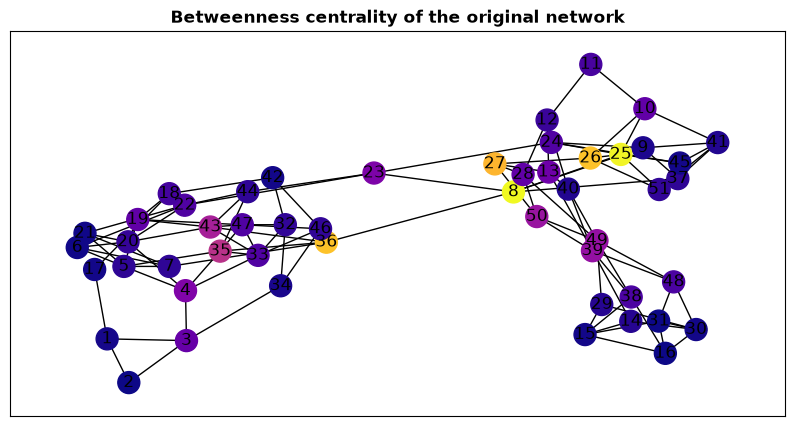

In [13]:
G_betw_centr = nx.betweenness_centrality(G)
bcentr_vals = [v for k, v in G_betw_centr.items()] # centrality list for heatmap

rGr_betw_centr = nx.betweenness_centrality(G_rand)
bcentr_vals_rGr = [v for k, v in rGr_betw_centr.items()] # centrality list for heatmap

plt.figure(figsize=(10, 5))
plt.title("Betweenness centrality of the original network", fontweight="bold")
nx.draw_networkx(G, 
        node_color=bcentr_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(bcentr_vals), 
        vmax=max(bcentr_vals), 
        pos=spring_layout,
        node_size=250
    )
plt.show()

# I identify the 8 most central nodes in the two networks
highest_Gbc_nodes = [k for k, v in sorted(G_betw_centr.items(), key=lambda item: item[1], reverse=True)][:8]
highest_Grandbc_nodes = [k for k, v in sorted(rGr_betw_centr.items(), key=lambda item: item[1], reverse=True)][:8]

**Observation**: nodes 8, 25, 26, 36, and 27 have a very high betweenness centrality compared to the other nodes.  
**Interpretation**: The network's information flow is centralised: eliminating the high-throughput nodes have would significantly disrupt the network. They also seem to be "bridges" that allow information to cross from one side to the other.

### 3.6.4. Eigenvector centrality

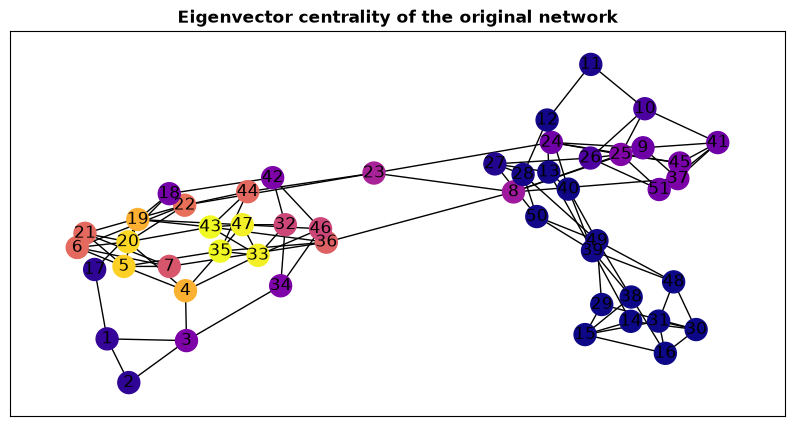

In [14]:
G_eigen_centr = nx.eigenvector_centrality(G, max_iter=500)
ecentr_vals = [v for k, v in G_eigen_centr.items()] # centrality list for heatmap

rGr_eigen_centr = nx.eigenvector_centrality(G_rand)
ecentr_vals_rGr = [v for k, v in rGr_eigen_centr.items()] # centrality list for heatmap

plt.figure(figsize=(10, 5))
plt.title("Eigenvector centrality of the original network", fontweight="bold")
nx.draw_networkx(G, 
        node_color=ecentr_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(ecentr_vals), 
        vmax=max(ecentr_vals), 
        pos=spring_layout,
        node_size=250
    )
plt.show()

# I identify the 8 most central nodes in the two networks
highest_Gec_nodes = [k for k, v in sorted(G_eigen_centr.items(), key=lambda item: item[1], reverse=True)][:8]
highest_Grandec_nodes = [k for k, v in sorted(rGr_eigen_centr.items(), key=lambda item: item[1], reverse=True)][:8]

**Observation**: nodes 43, 35, 33, and 47 have a very high eigenvector centrality, and nodes 20, 5, 4, and 19 a high one, compared to the other nodes; there is no node with high centrality on the righ side of the network.  
**Interpretation**: The eight aforementioned nodes form a "core" of influence, where each important node reinforces the other nodes' importance. Interestingly, none of the nodes is a significant information hub or source, highlighting the difference between each centrality "importance".

### 3.6.5. Centrality overview

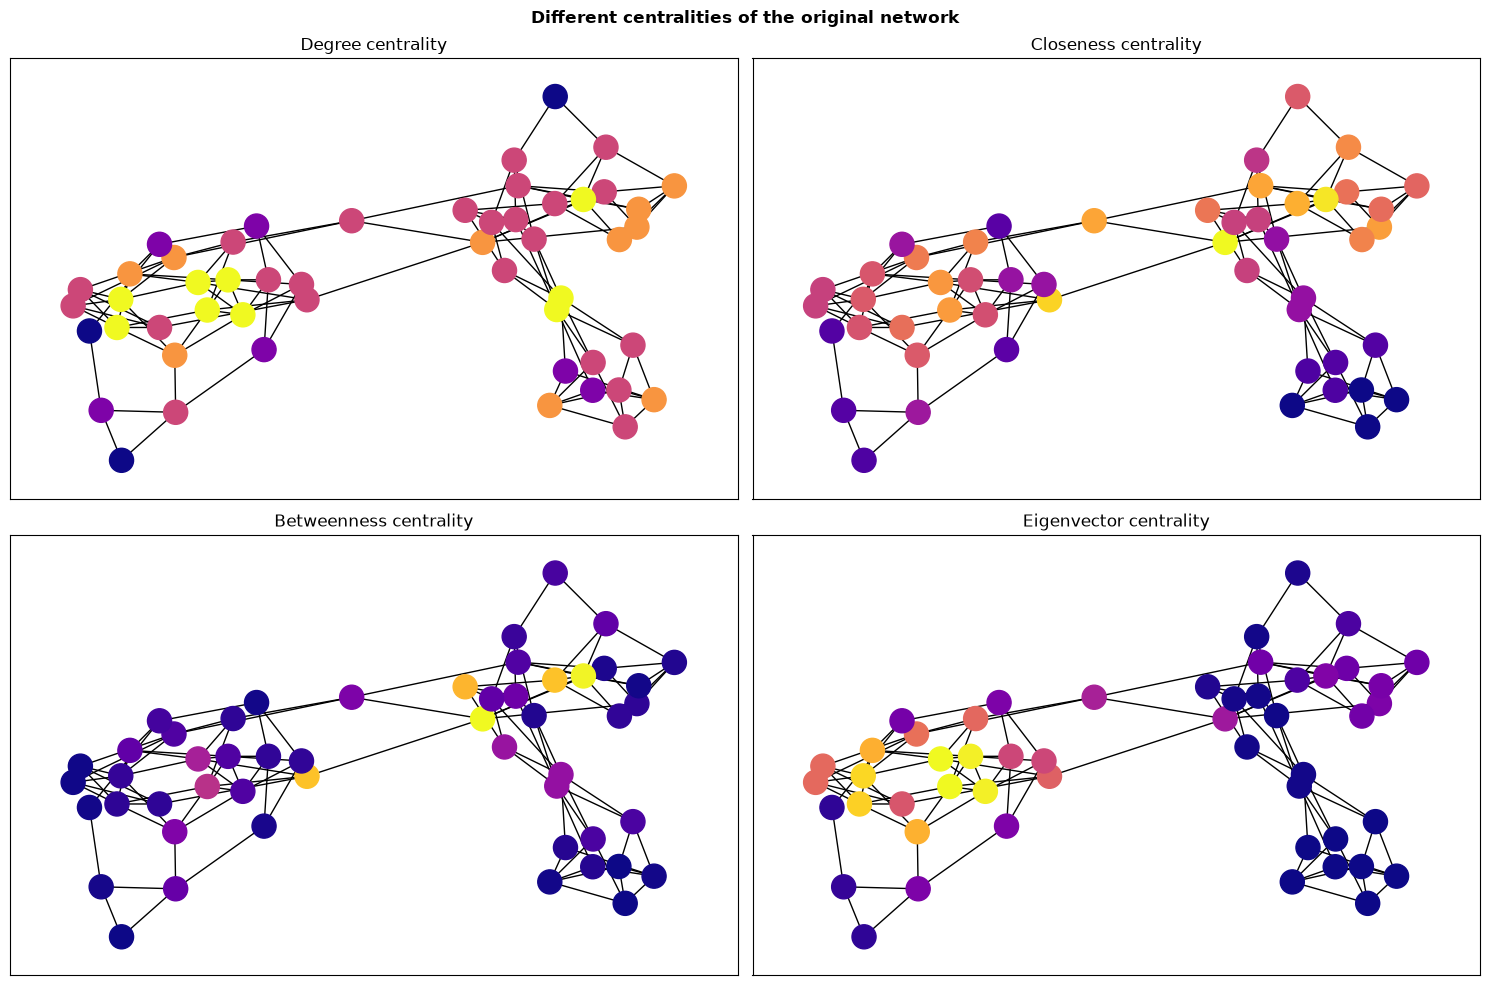

In [15]:
fig_centrality = plt.figure(figsize=(15, 10))
plt.suptitle("Different centralities of the original network", fontweight="bold")

fig_centrality.add_subplot(221, title="Degree centrality",)
nx.draw_networkx(G, node_color=dcentr_vals, cmap=colormaps.get_cmap('plasma'), vmin=min(dcentr_vals), vmax=max(dcentr_vals), pos=spring_layout, with_labels=False)

fig_centrality.add_subplot(222, title="Closeness centrality")
nx.draw_networkx(G, node_color=ccentr_vals, cmap=colormaps.get_cmap('plasma'), vmin=min(ccentr_vals), vmax=max(ccentr_vals), pos=spring_layout, with_labels=False)

fig_centrality.add_subplot(223, title="Betweenness centrality")
nx.draw_networkx(G, node_color=bcentr_vals, cmap=colormaps.get_cmap('plasma'), vmin=min(bcentr_vals), vmax=max(bcentr_vals), pos=spring_layout, with_labels=False)

fig_centrality.add_subplot(224, title="Eigenvector centrality")
nx.draw_networkx(G, node_color=ecentr_vals, cmap=colormaps.get_cmap('plasma'), vmin=min(ecentr_vals), vmax=max(ecentr_vals), pos=spring_layout, with_labels=False)

plt.tight_layout()
plt.show()

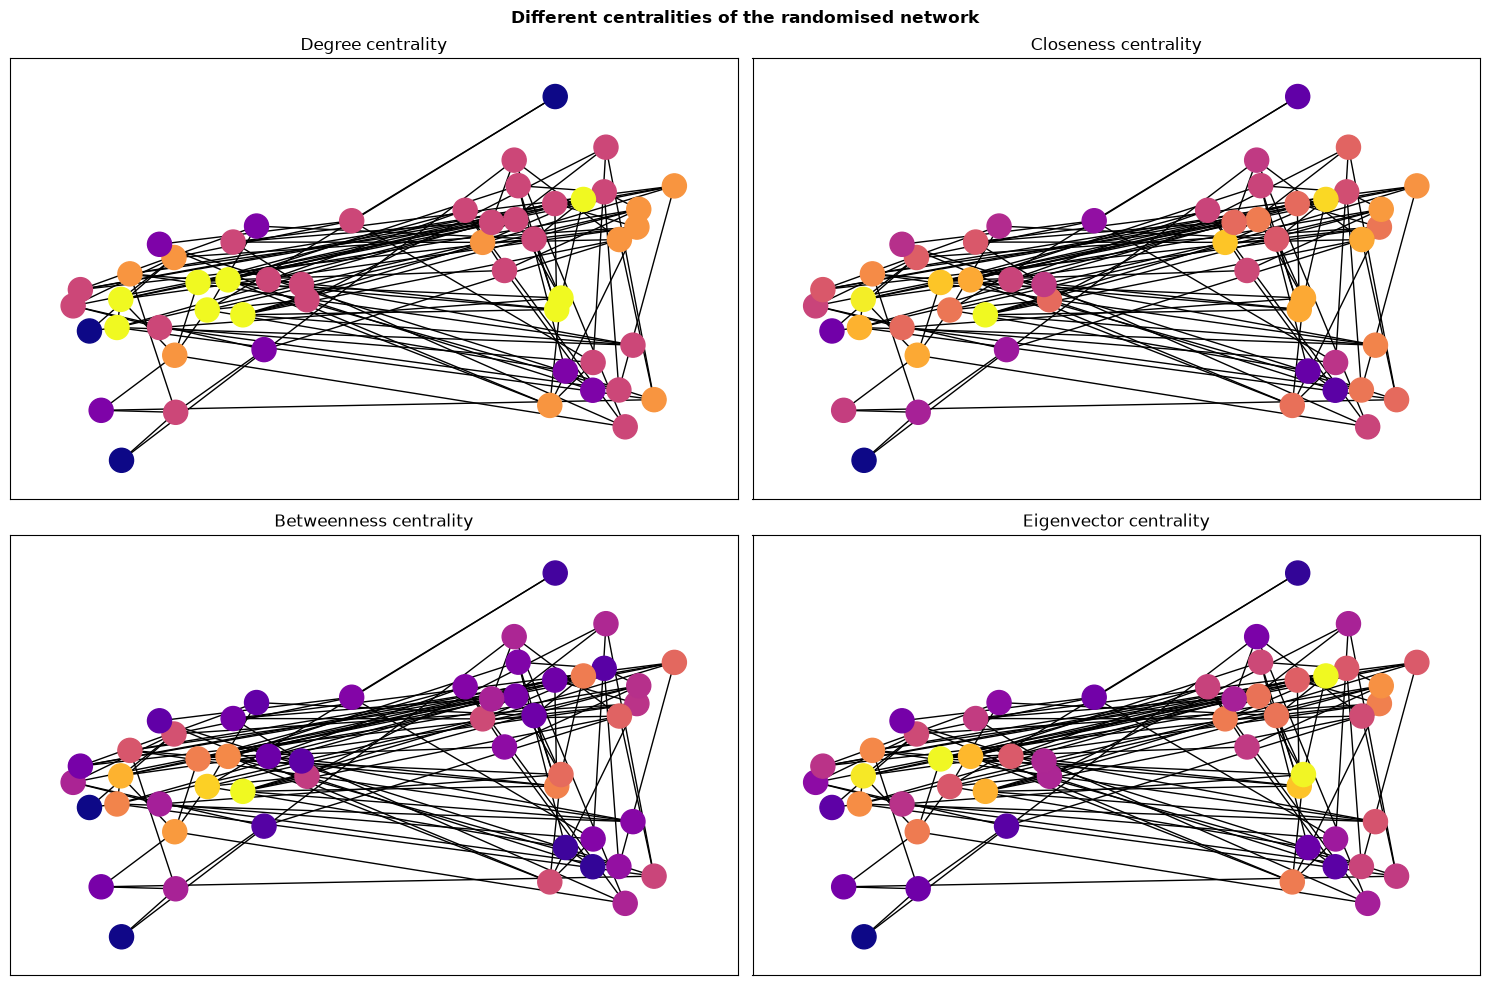

In [16]:
fig_rand_centrality = plt.figure(figsize=(15, 10))
plt.suptitle("Different centralities of the randomised network", fontweight="bold")

fig_rand_centrality.add_subplot(221, title="Degree centrality",)
nx.draw_networkx(G_rand, node_color=dcentr_vals_rGr, cmap=colormaps.get_cmap('plasma'), vmin=min(dcentr_vals_rGr), vmax=max(dcentr_vals_rGr), pos=spring_layout, with_labels=False)

fig_rand_centrality.add_subplot(222, title="Closeness centrality")
nx.draw_networkx(G_rand, node_color=ccentr_vals_rGr, cmap=colormaps.get_cmap('plasma'), vmin=min(ccentr_vals_rGr), vmax=max(ccentr_vals_rGr), pos=spring_layout, with_labels=False)

fig_rand_centrality.add_subplot(223, title="Betweenness centrality")
nx.draw_networkx(G_rand, node_color=bcentr_vals_rGr, cmap=colormaps.get_cmap('plasma'), vmin=min(bcentr_vals_rGr), vmax=max(bcentr_vals_rGr), pos=spring_layout, with_labels=False)

fig_rand_centrality.add_subplot(224, title="Eigenvector centrality")
nx.draw_networkx(G_rand, node_color=ecentr_vals_rGr, cmap=colormaps.get_cmap('plasma'), vmin=min(ecentr_vals_rGr), vmax=max(ecentr_vals_rGr), pos=spring_layout, with_labels=False)

plt.tight_layout()
plt.show()

#### 3.6.5.1. Centrality correlations

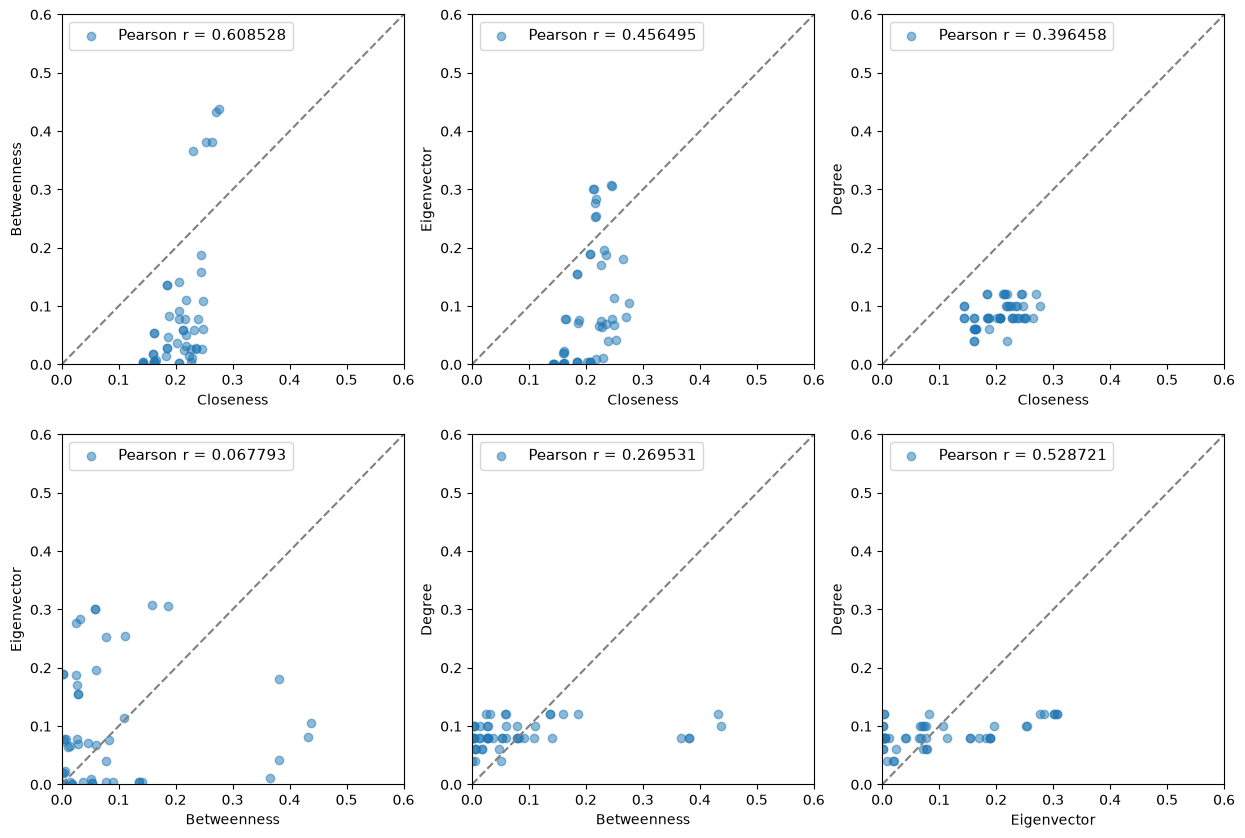

In [17]:
# I centralise all the centralities in one DataFrame for ease of use when plotting correlations
df = pd.DataFrame({
        'Degree': dcentr_vals,
        'Closeness': ccentr_vals,
        'Betweenness': bcentr_vals,
        'Eigenvector': ecentr_vals
    })

corr_df = df.corr(method='pearson') # I calculate the Pearson correlation between each pair of centralities

fig_corr = plt.figure(figsize=(15, 10))

fig_corr.add_subplot(231)
plt.scatter(ccentr_vals, bcentr_vals, alpha=0.5, label=f"Pearson r = {corr_df['Closeness']['Betweenness']:.6f}")
plt.legend(loc='upper left', frameon=True, fontsize=11)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, zorder=1)
plt.xlabel("Closeness")
plt.ylabel("Betweenness")
plt.axis((0, 0.6, 0, 0.6))

fig_corr.add_subplot(232)
plt.scatter(ccentr_vals, ecentr_vals, alpha=0.5, label=f"Pearson r = {corr_df['Closeness']['Eigenvector']:.6f}")
plt.legend(loc='upper left', frameon=True, fontsize=11)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, zorder=1)
plt.xlabel("Closeness")
plt.ylabel("Eigenvector")
plt.axis((0, 0.6, 0, 0.6))

fig_corr.add_subplot(233)
plt.scatter(ccentr_vals, dcentr_vals, alpha=0.5, label=f"Pearson r = {corr_df['Closeness']['Degree']:.6f}")
plt.legend(loc='upper left', frameon=True, fontsize=11)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, zorder=1)
plt.xlabel("Closeness")
plt.ylabel("Degree")
plt.axis((0, 0.6, 0, 0.6))

fig_corr.add_subplot(234)
plt.scatter(bcentr_vals, ecentr_vals, alpha=0.5, label=f"Pearson r = {corr_df['Betweenness']['Eigenvector']:.6f}")
plt.legend(loc='upper left', frameon=True, fontsize=11)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, zorder=1)
plt.xlabel("Betweenness")
plt.ylabel("Eigenvector")
plt.axis((0, 0.6, 0, 0.6))

fig_corr.add_subplot(235)
plt.scatter(bcentr_vals, dcentr_vals, alpha=0.5, label=f"Pearson r = {corr_df['Betweenness']['Degree']:.6f}")
plt.legend(loc='upper left', frameon=True, fontsize=11)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, zorder=1)
plt.xlabel("Betweenness")
plt.ylabel("Degree")
plt.axis((0, 0.6, 0, 0.6))

fig_corr.add_subplot(236)
plt.scatter(ecentr_vals, dcentr_vals, alpha=0.5, label=f"Pearson r = {corr_df['Eigenvector']['Degree']:.6f}")
plt.legend(loc='upper left', frameon=True, fontsize=11)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, zorder=1)
plt.ylabel("Degree")
plt.xlabel("Eigenvector")
plt.axis((0, 0.6, 0, 0.6))

plt.show()

### 3.6.6. Centrality conclusions

In [18]:
print(f"For G:\n  - nodes with highest degree centrality: {highest_centr}\n" + 
      f"  - nodes with highest closeness centrality: {highest_Gcc_nodes}\n" + 
      f"  - nodes with highest betweenness centrality: {highest_Gbc_nodes}\n" +
      f"  - nodes with highest eigenvector centrality: {highest_Gec_nodes}")

For G:
  - nodes with highest degree centrality: ['5', '20', '33', '35', '25', '39', '43', '47', '49']
  - nodes with highest closeness centrality: ['8', '25', '36', '26', '23', '24', '37', '35']
  - nodes with highest betweenness centrality: ['8', '25', '26', '36', '27', '35', '43', '50']
  - nodes with highest eigenvector centrality: ['43', '35', '33', '47', '20', '5', '4', '19']


##### 1. Global hubs (multiple high centralities)

  **Observation**: Nodes 35 and 25 appear near the top across all four centrality measures.  
  **Interpretation**: These nodes are, highly connected locally, sit along critical walks, and lie near the center of the entire network graph. Biologically, in an enzyme structural graph, these are likely part of the main structural core.


Graph with 49 nodes and 98 edges



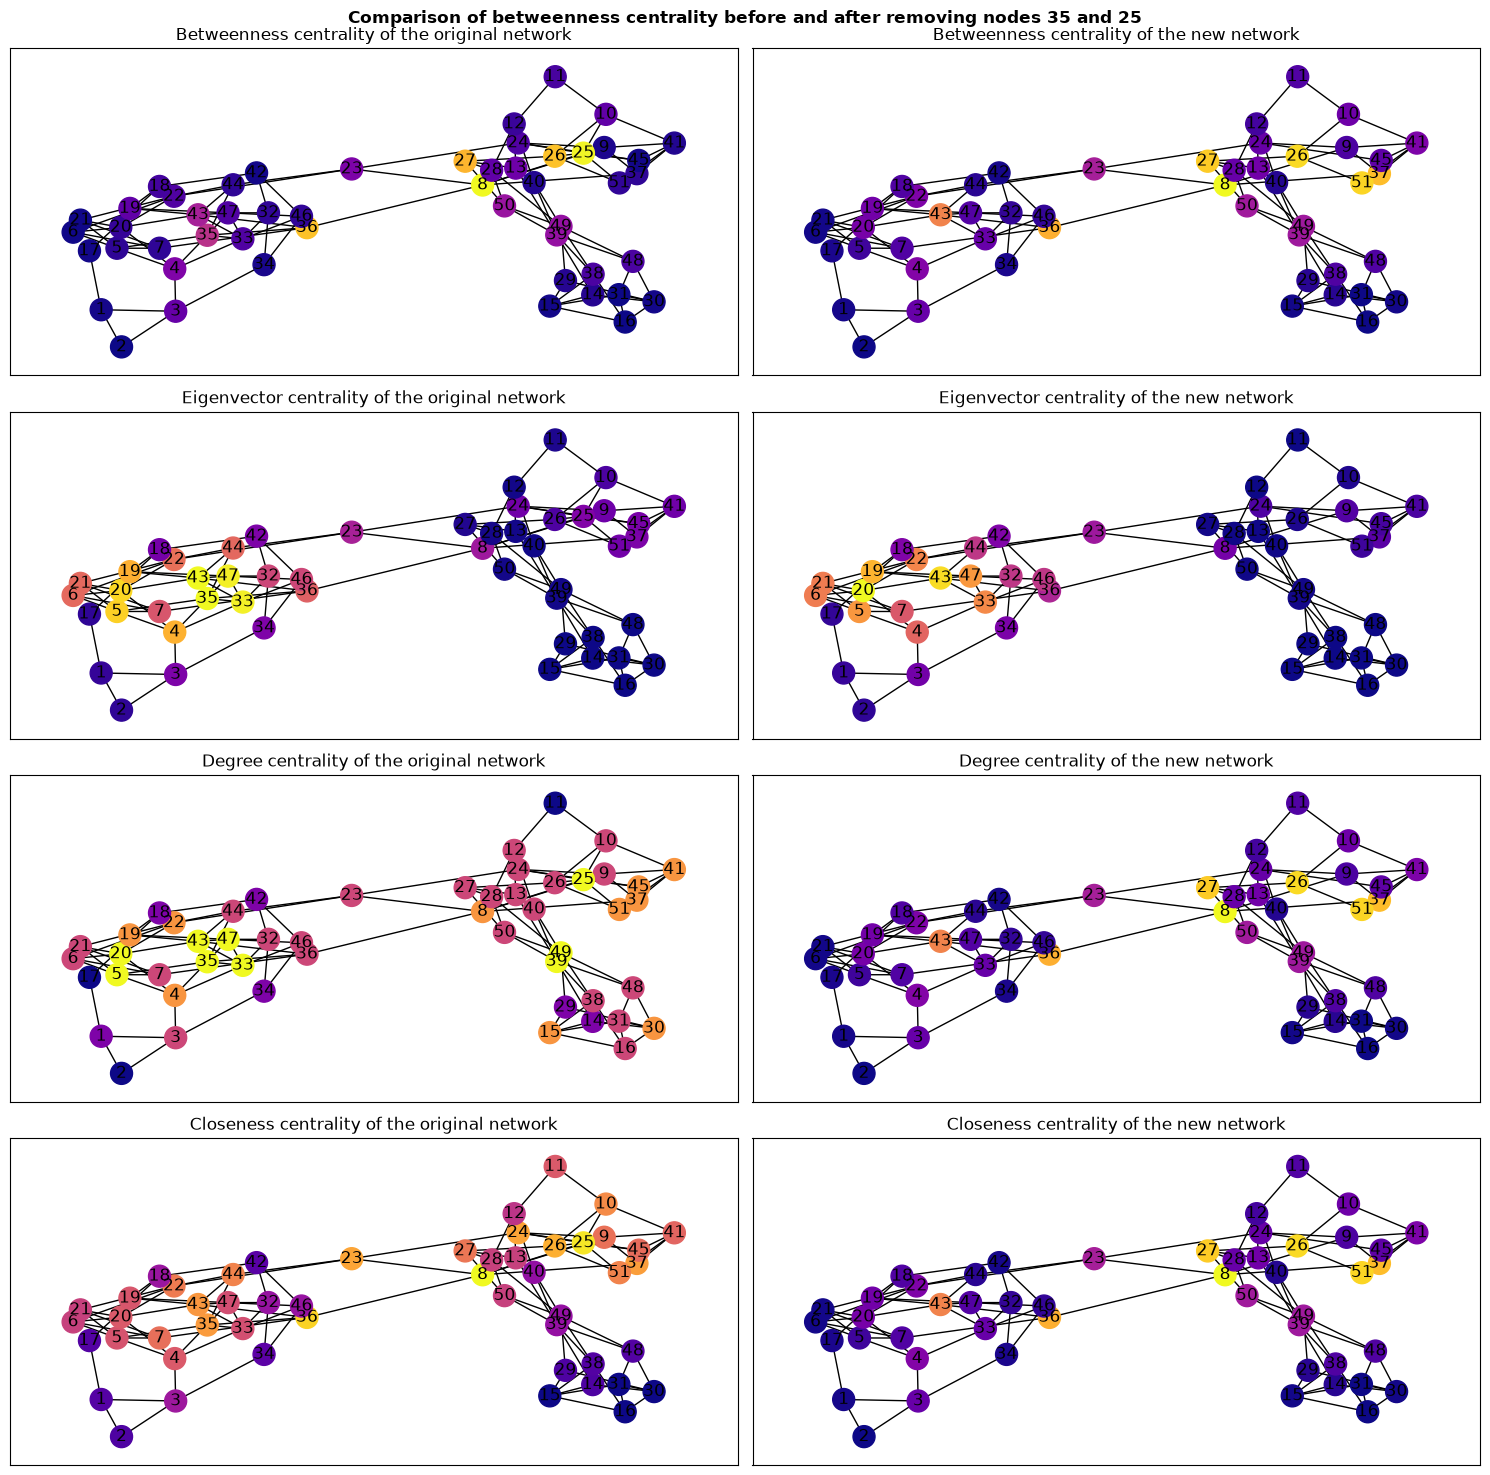

In [19]:
# to investigate the effects removing nodes 25 and 35 would have on the network, I deep-copy the network and eliminate the nodes
G1 = nx.Graph(G)
G1.remove_nodes_from(['25', '35'])
print(f"\n{G1}\n")

fig_G1 = plt.figure(figsize=(15, 15))
plt.suptitle("Comparison of betweenness centrality before and after removing nodes 35 and 25", fontweight="bold")

G1_bc = nx.betweenness_centrality(G1)
G1_bc_vals = [v for k, v in G1_bc.items()]

G1_ec = nx.eigenvector_centrality(G1, max_iter=500)
G1_ec_vals = [v for k, v in G1_ec.items()]

G1_dc = nx.betweenness_centrality(G1)
G1_dc_vals = [v for k, v in G1_dc.items()]

G1_cc = nx.betweenness_centrality(G1)
G1_cc_vals = [v for k, v in G1_cc.items()]

fig_G1.add_subplot(422, title="Betweenness centrality of the new network")
nx.draw_networkx(G1, 
        node_color=G1_bc_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(G1_bc_vals), 
        vmax=max(G1_bc_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G1.add_subplot(421, title="Betweenness centrality of the original network")
nx.draw_networkx(G, 
        node_color=bcentr_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(bcentr_vals), 
        vmax=max(bcentr_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G1.add_subplot(424, title="Eigenvector centrality of the new network")
nx.draw_networkx(G1, 
        node_color=G1_ec_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(G1_ec_vals), 
        vmax=max(G1_ec_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G1.add_subplot(423, title="Eigenvector centrality of the original network")
nx.draw_networkx(G, 
        node_color=ecentr_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(ecentr_vals), 
        vmax=max(ecentr_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G1.add_subplot(426, title="Degree centrality of the new network")
nx.draw_networkx(G1, 
        node_color=G1_dc_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(G1_dc_vals), 
        vmax=max(G1_dc_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G1.add_subplot(425, title="Degree centrality of the original network")
nx.draw_networkx(G, 
        node_color=dcentr_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(dcentr_vals), 
        vmax=max(dcentr_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G1.add_subplot(428, title="Closeness centrality of the new network")
nx.draw_networkx(G1, 
        node_color=G1_cc_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(G1_cc_vals), 
        vmax=max(G1_cc_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G1.add_subplot(427, title="Closeness centrality of the original network")
nx.draw_networkx(G, 
        node_color=ccentr_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(ccentr_vals), 
        vmax=max(ccentr_vals), 
        pos=spring_layout,
        node_size=250
    )

plt.tight_layout()
plt.show()

We can see that removing nodes 25 and 35 changes significantly the centrality in the network. In terms of betweenness, nodes 37 and 51 go from having almost no importance to being new information bottlenecks; in other words, they are forced to take over the role of nodes 25 and 35 in order to preserve network functionality.

On the other hand, eigenvector, degree and closeness centralities move away from previously important nodes and concentrate in just a few nodes. This shows that the network relies on a few hubs which, if removed, impede the network's ability to broadcast information to its components.

##### 2. "Bridge" nodes / bottlenecks (high betweenness and closeness, lower degree)

 **Observation**: Nodes 8 and 26 rank at the top for closeness and betweenness, but they do not appear in the top lists for degree or eigenvector centrality.  
 **Interpretation**: These nodes act as critical articulation points or structural bridges. Even if they have moderate degree, they bridge distinct structural domains or modules. Removing them would significantly increase path lengths or potentially fragment the network into disconnected subgraphs. 



Graph with 49 nodes and 101 edges



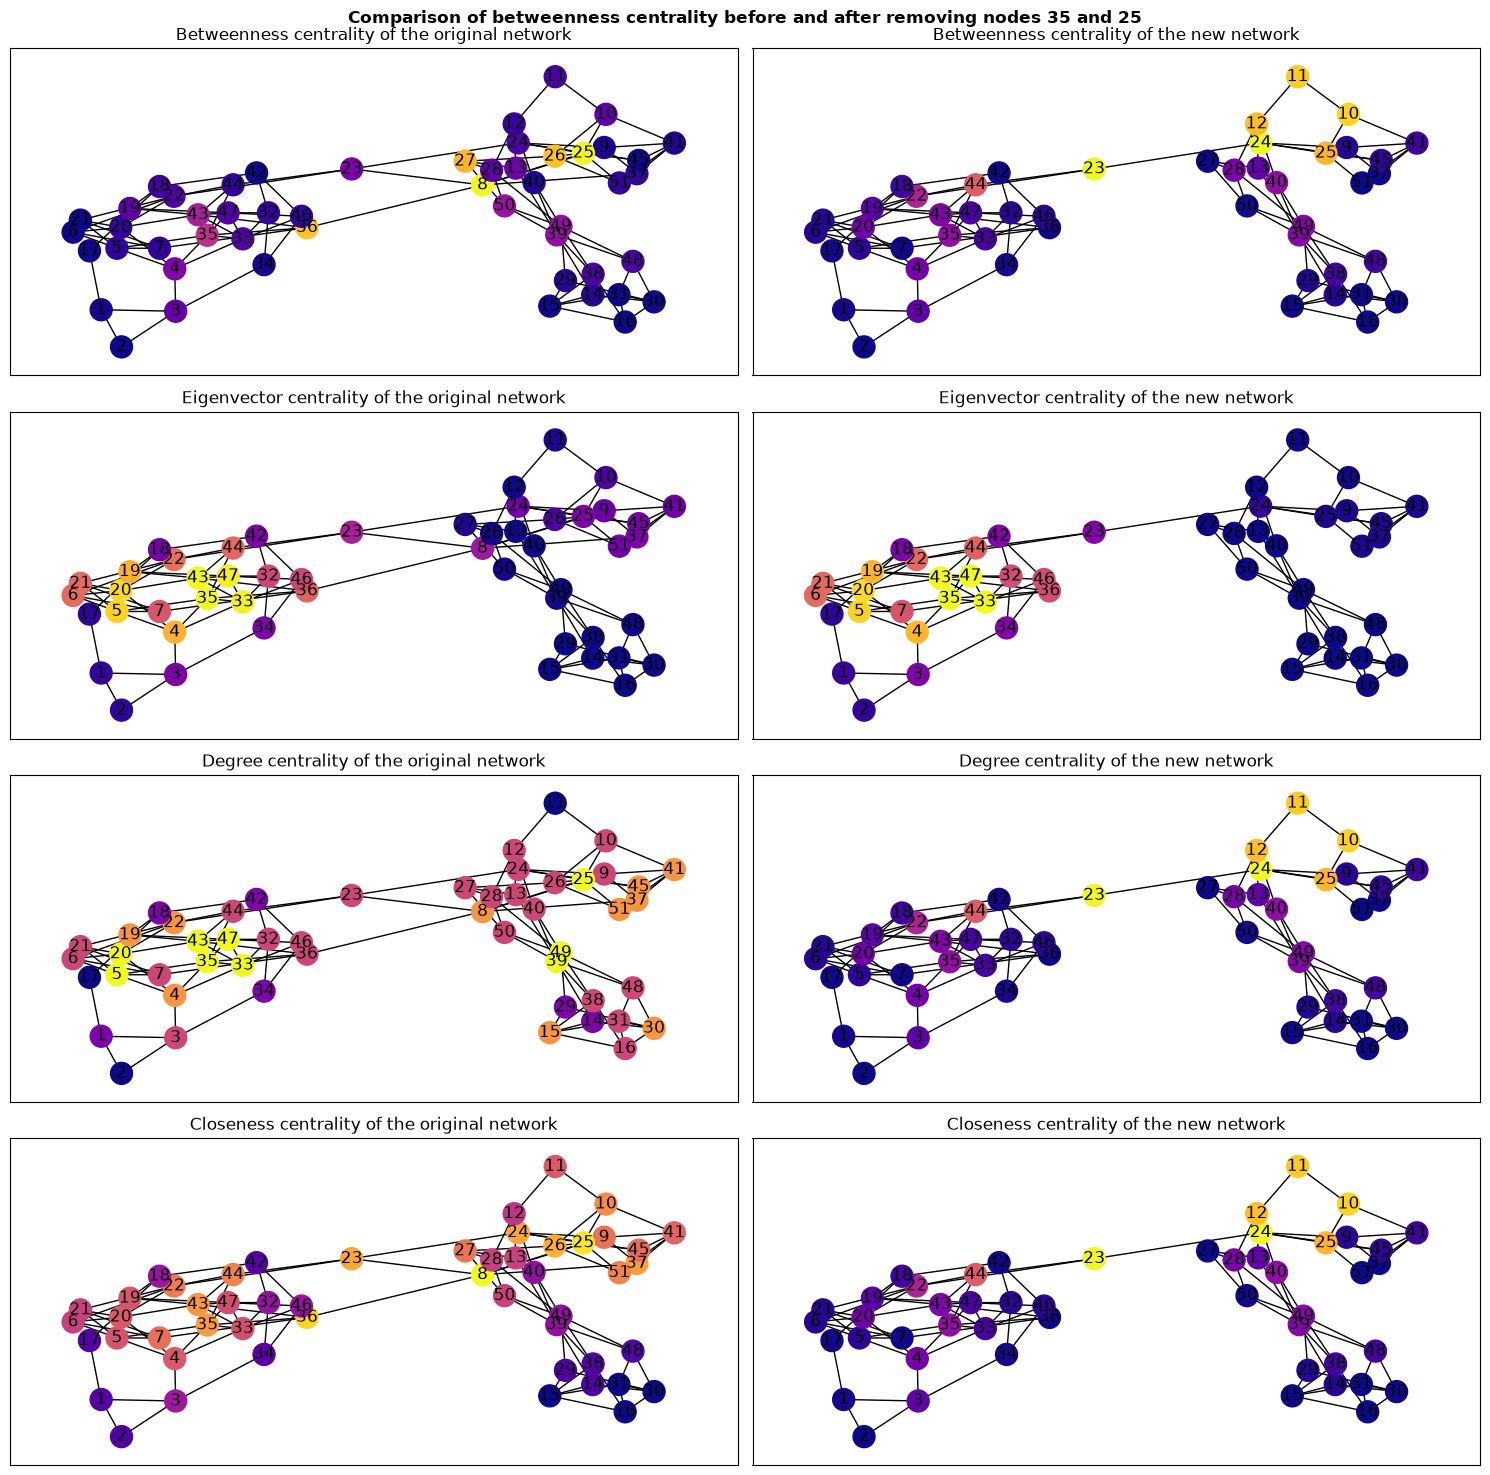

In [20]:
# to investigate the effects removing nodes 8 and 26 would have on the network, I deep-copy the network and eliminate the nodes
G2 = nx.Graph(G)
G2.remove_nodes_from(['8', '26'])
print(f"\n{G2}\n")

fig_G2 = plt.figure(figsize=(15, 15))
plt.suptitle("Comparison of betweenness centrality before and after removing nodes 35 and 25", fontweight="bold")

G2_bc = nx.betweenness_centrality(G2)
G2_bc_vals = [v for k, v in G2_bc.items()]

G2_ec = nx.eigenvector_centrality(G2, max_iter=500)
G2_ec_vals = [v for k, v in G2_ec.items()]

G2_dc = nx.betweenness_centrality(G2)
G2_dc_vals = [v for k, v in G2_dc.items()]

G2_cc = nx.betweenness_centrality(G2)
G2_cc_vals = [v for k, v in G2_cc.items()]

fig_G2.add_subplot(422, title="Betweenness centrality of the new network")
nx.draw_networkx(G2, 
        node_color=G2_bc_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(G2_bc_vals), 
        vmax=max(G2_bc_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G2.add_subplot(421, title="Betweenness centrality of the original network")
nx.draw_networkx(G, 
        node_color=bcentr_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(bcentr_vals), 
        vmax=max(bcentr_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G2.add_subplot(424, title="Eigenvector centrality of the new network")
nx.draw_networkx(G2, 
        node_color=G2_ec_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(G2_ec_vals), 
        vmax=max(G2_ec_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G2.add_subplot(423, title="Eigenvector centrality of the original network")
nx.draw_networkx(G, 
        node_color=ecentr_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(ecentr_vals), 
        vmax=max(ecentr_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G2.add_subplot(426, title="Degree centrality of the new network")
nx.draw_networkx(G2, 
        node_color=G2_dc_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(G2_dc_vals), 
        vmax=max(G2_dc_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G2.add_subplot(425, title="Degree centrality of the original network")
nx.draw_networkx(G, 
        node_color=dcentr_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(dcentr_vals), 
        vmax=max(dcentr_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G2.add_subplot(428, title="Closeness centrality of the new network")
nx.draw_networkx(G2, 
        node_color=G2_cc_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(G2_cc_vals), 
        vmax=max(G2_cc_vals), 
        pos=spring_layout,
        node_size=250
    )

fig_G2.add_subplot(427, title="Closeness centrality of the original network")
nx.draw_networkx(G, 
        node_color=ccentr_vals, 
        cmap=colormaps.get_cmap('plasma'), 
        vmin=min(ccentr_vals), 
        vmax=max(ccentr_vals), 
        pos=spring_layout,
        node_size=250
    )

plt.tight_layout()
plt.show()

Despite not being as "popular" across the board as nodes 25 and 35, eliminating nodes 8 and 26 has a higher impact on the network as a whole. Since they are "bridge" nodes, deleting them effectively separates the network in two components: one with very high betweenness, closeness and degree centrality ("central component"), formed by nodes 23, 24, 25, 11, 12, and 10, and the rest of the network, which has very low centrality. This is especially interesting since the two nodes have low degree centrality, and therefore a supposedly low influence in the network. 

**Interpretation**:
The aforementioned separation makes the network more susceptible to attacks: if eliminating two nodes makes such a significant split in the network's flow of information, eliminating the "central component" would probably effectively disable the network. 

Just like before, removing only two nodes markedly disrupts the network's activity, making it unable to disseminate information to most of its nodes. This was hinted at in the previous experiment as well: when eliminating nodes 25 and 35, nodes 8 and 26 became more central in term of degree and closeness. 

# 4. Mesoscopic properties


## 4.1. Communities

COMMUNITY STRUCTURE & MODULARITY
Louvain - Identified Communities (seed 2):	4
Louvain - Modularity Score (Q) (seed 2):	0.6247

Louvain - Identified Communities (seed 42):	5
Louvain - Modularity Score (Q) (seed 42):	0.6129

Fast greedy - Identified Communities:		4
Fast greedy - Modularity Score (Q):		0.6261


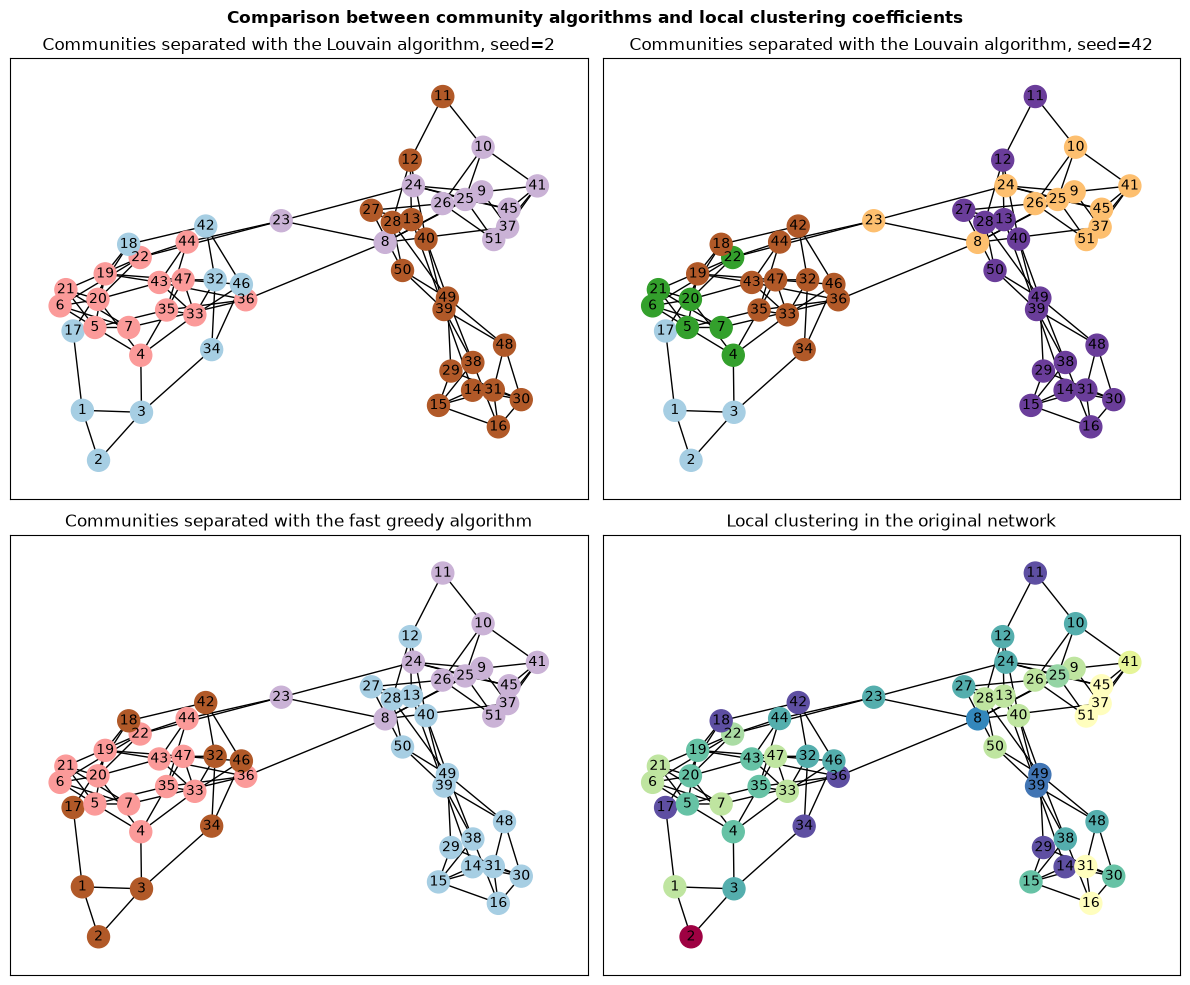

In [21]:

louv_comm = nx.community.louvain_communities(G, seed=2)
modularity_louv = nx.community.modularity(G, louv_comm)

louv_comm_42 = nx.community.louvain_communities(G, seed=42)
modularity_louv_42 = nx.community.modularity(G, louv_comm_42)

greedy_comm = nx.community.greedy_modularity_communities(G)
modularity_greedy = nx.community.modularity(G, greedy_comm)


print("=" * 40)
print("COMMUNITY STRUCTURE & MODULARITY")
print("=" * 40)
print(f"Louvain - Identified Communities (seed 2):\t{len(louv_comm)}")
print(f"Louvain - Modularity Score (Q) (seed 2):\t{modularity_louv:.4f}\n")
print(f"Louvain - Identified Communities (seed 42):\t{len(louv_comm_42)}")
print(f"Louvain - Modularity Score (Q) (seed 42):\t{modularity_louv_42:.4f}\n")
print(f"Fast greedy - Identified Communities:\t\t{len(greedy_comm)}")
print(f"Fast greedy - Modularity Score (Q):\t\t{modularity_greedy:.4f}")

# I map each node to its community index; this will help display each community with a different colour
node_to_louv_comm = {}
for comm_id, comm in enumerate(louv_comm):
    for node in comm:
        node_to_louv_comm[node] = comm_id

# Because node_color needs an array of values, I create a color list that has the same order as the nodes in G
node_louv_colors = [node_to_louv_comm[node] for node in G.nodes()]

node_to_louv_comm_42 = {}
for comm_id, comm in enumerate(louv_comm_42):
    for node in comm:
        node_to_louv_comm_42[node] = comm_id

node_louv_42_colors = [node_to_louv_comm_42[node] for node in G.nodes()]

node_to_greedy_comm = {}
for comm_id, comm in enumerate(greedy_comm):
    for node in comm:
        node_to_greedy_comm[node] = comm_id

node_greedy_colors = [node_to_greedy_comm[node] for node in G.nodes()]

fig_comms = plt.figure(figsize=(12, 10))
plt.suptitle("Comparison between community algorithms and local clustering coefficients", fontsize=12, fontweight='bold')

fig_comms.add_subplot(221, title="Communities separated with the Louvain algorithm, seed=2")
nx.draw_networkx(G, 
        pos=spring_layout,
        node_color=node_louv_colors,
        cmap=plt.cm.Paired,
        node_size=250,
        font_size=10
    )

fig_comms.add_subplot(222, title="Communities separated with the Louvain algorithm, seed=42")
nx.draw_networkx(G, 
        pos=spring_layout,
        node_color=node_louv_42_colors,
        cmap=plt.cm.Paired,
        node_size=250,
        font_size=10
    )


fig_comms.add_subplot(223, title="Communities separated with the fast greedy algorithm")
nx.draw_networkx(G, 
        pos=spring_layout,
        node_color=node_greedy_colors,
        cmap=plt.cm.Paired,
        node_size=250,
        font_size=10
    )

fig_comms.add_subplot(224, title="Local clustering in the original network")
nx.draw_networkx(G, 
        node_color=clust_vals, 
        cmap=plt.cm.Spectral_r,
        vmin=min(clust_vals), 
        vmax=max(clust_vals), 
        pos=spring_layout,
        node_size=250,
        font_size=10
    )

plt.tight_layout()
plt.show()

Looking at these visualisations, we see that, if the number of communities is the same, the communities are almost identical regardless of the algorithm used. However, since the Louvain method is non-deterministic, it is possible we obtain 5 communities instead of four; while the right-hand side of the network keeps the same split, the left-hand side has about half of the nodes of each community grouped together in a fith community.

Regardless of community detection algorithm used, some nodes always act as "community gateways":  
- 8-36 and 23-22 for the left-right split
- 3-4 for the left-hand side top-bottom split
- 11-(10 or 12) and 27-26 for the right-hand side split

This correlates well with the local clustering coefficients depicted in the botoom-right subplot: at least one node in all pairs has a low coefficient (dark green or blue), meaning it is linked to nodes which aren't interconnected, so they have a lower chance of being all in the same community. We also see that the nodes with higher clustering coefficients are part of the same respective community, as mentioned in section 3.5.

# 5. Final network analyses

## 5.1. Statistical significance of the properties

For a more robust analysis of the network, I will calculate the mean and standard deviation of the clustering and assortativity coefficients compared to a baseline given by 1000 network randomisations with degree preservation.

In [22]:

n_iterations = 1000 # number of randomized null models to generate
random_clustering_coeffs = []
random_assortativity_coeffs = []

for seed in range(n_iterations):
    G_random = nx.random_reference(G, seed=seed) # I create a different randomised network in each iteration
    random_clustering_coeffs.append(nx.average_clustering(G_random)) # I store the clustering and assortativity coefficients of randomised each network
    random_assortativity_coeffs.append(nx.degree_pearson_correlation_coefficient(G_random))

# I compute the mean, standard deviation, and z-score for clustering...
mean_rand_clust = np.mean(random_clustering_coeffs)
std_rand_clust = np.std(random_clustering_coeffs)
z_score_clust = (G_clustering_coeff - mean_rand_clust) / std_rand_clust

# ...and for assortativity
mean_rand_assort = np.mean(random_assortativity_coeffs)
std_rand_assort = np.std(random_assortativity_coeffs)
z_score_assort = (G_pears_assort_coeff - mean_rand_assort) / std_rand_assort

print('=' * 60)
print("STATISTICAL SIGNIFICANCE OF CLUSTERING AND ASSORTATIVITY")
print('=' * 60)
print(f"Real Clustering:\t\t{G_clustering_coeff:.4f}")
print(f"Null Model Mean Clustering: \t{mean_rand_clust:.4f} (± {std_rand_clust:.4f})")
print(f"Z-Score Clustering: \t\t{z_score_clust:.2f}\n")
print(f"Real Assortativity: \t\t{G_pears_assort_coeff:.4f}")
print(f"Null Model Mean Assortativity: \t{mean_rand_assort:.4f} (± {std_rand_assort:.4f})")
print(f"Z-Score Assortativity: \t\t{z_score_assort:.2f}")

STATISTICAL SIGNIFICANCE OF CLUSTERING AND ASSORTATIVITY
Real Clustering:		0.2379
Null Model Mean Clustering: 	0.0617 (± 0.0218)
Z-Score Clustering: 		8.08

Real Assortativity: 		0.1693
Null Model Mean Assortativity: 	-0.0039 (± 0.0906)
Z-Score Assortativity: 		1.91


The real network exhibits significantly higher local clustering (0.2379) compared to the random baseline (0.0617 $\pm$ 0.0218). The Z-score of 8.08 shows that the network's clustering is not the result of chance, but a significant structural property pointing to strong local transitivity and community structure.

Degree assortativity on the other hand is mildly positive (0.1693) compared to the null model (-0.0039 $\pm$ 0.0906), yielding a Z-score of 1.91. While this suggests a trend toward hub-to-hub connectivity, it remains on the boundary of statistical significance.

## 5.2. Network classification

1. Scale-free  
Scale-free networks are characterised by heavy-tailed degree distributions that follow the power law. The analysed network does not have such a degree distribution, therefore it is **not scale-free**. 

2. Random  
I proved in section 5.1 that this network has a much higher clustering coefficient than a random distribution. This, together with the tendency to assortativity shown in section 5.1 and 3.4, proves that the analysed network is **not random**.

3. Small-world  
Typically, small-world networks have a higher-than-random clustering coefficient, while presenting an average path length close to that of a random network. Moreover, their average distance grows only as the logarithm of its size: $⟨d⟩ ∝ ln N$.  
  In the case of our network, while the clustering coefficient is indeed higher, so is the average path length: 5.04 vs. the 2.8 for randomised network vs. 2.89 theoretical random logarithmic expectation (see below). This and the high modularity (Q = 0.62) show that the network is organised in modular communities connected by critical bridge nodes, rather than long-range shortcuts. Even so, the average path length is quite short; I would say that the analysed network can be classified as a **weakly-defined small-world network**.  

In [23]:
avg_dist = np.log(N) / np.log(avg_degree) # I calculate the theoretical average distance using ln(N)/ln(<k>)
print(f"Theoretical logarithmic expectation: {avg_dist:.4f}")
print(f"Actual network path length: {avg_path_length}")

Theoretical logarithmic expectation: 2.6897
Actual network path length: 5.04235294117647


# 6. Disclosure of AI use

Most of this notebook has been the work of Internet searches, class material perusings, and package documentations. However, I used generative AI (Gemini model 3) for the following tasks:

- some plots, notably centrality correlations and colouring the communities;
- rewording some phrases (e.g. from "These nodes are the most 'popular', having the most direct connections." to "These nodes serve as densely connected local hubs");
- explaining the results in the context of an enzymatic structure.
